In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
df=pd.read_csv("/content/healthcare_preprocessed (1) (1).csv")

In [ ]:
df.head()

,Name,Age,Gender,Blood_Type,Medical_Condition,Admission_Date,Doctor,Hospital,Insurance_Provider,Billing_Amount,Room Number,Admission_Type,Discharge_Date,Medication,Test_Results,Length_of_Stay,Age_Group,Admission_Urgency
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328.0,Urgent,2024-02-02,Paracetamol,Normal,2.0,19-30,Urgent
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265.0,Emergency,2019-08-26,Ibuprofen,Inconclusive,6.0,61-75,Emergency
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205.0,Emergency,2022-10-07,Aspirin,Normal,15.0,76+,Emergency
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450.0,Elective,2020-12-18,Ibuprofen,Abnormal,30.0,19-30,Elective
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458.0,Urgent,2022-10-09,Penicillin,Abnormal,20.0,31-45,Urgent


In [ ]:
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Number of rows: 18807
Number of columns: 18


In [ ]:
print(df.columns.tolist())

['Name', 'Age', 'Gender', 'Blood_Type', 'Medical_Condition', 'Admission_Date', 'Doctor', 'Hospital', 'Insurance_Provider', 'Billing_Amount', 'Room Number', 'Admission_Type', 'Discharge_Date', 'Medication', 'Test_Results', 'Length_of_Stay', 'Age_Group', 'Admission_Urgency']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18807 entries, 0 to 18806
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                18807 non-null  object 
 1   Age                 18807 non-null  int64  
 2   Gender              18807 non-null  object 
 3   Blood_Type          18807 non-null  object 
 4   Medical_Condition   18807 non-null  object 
 5   Admission_Date      18807 non-null  object 
 6   Doctor              18806 non-null  object 
 7   Hospital            18806 non-null  object 
 8   Insurance_Provider  18806 non-null  object 
 9   Billing_Amount      18806 non-null  float64
 10  Room Number         18806 non-null  float64
 11  Admission_Type      18806 non-null  object 
 12  Discharge_Date      18806 non-null  object 
 13  Medication          18806 non-null  object 
 14  Test_Results        18806 non-null  object 
 15  Length_of_Stay      18806 non-null  float64
 16  Age_

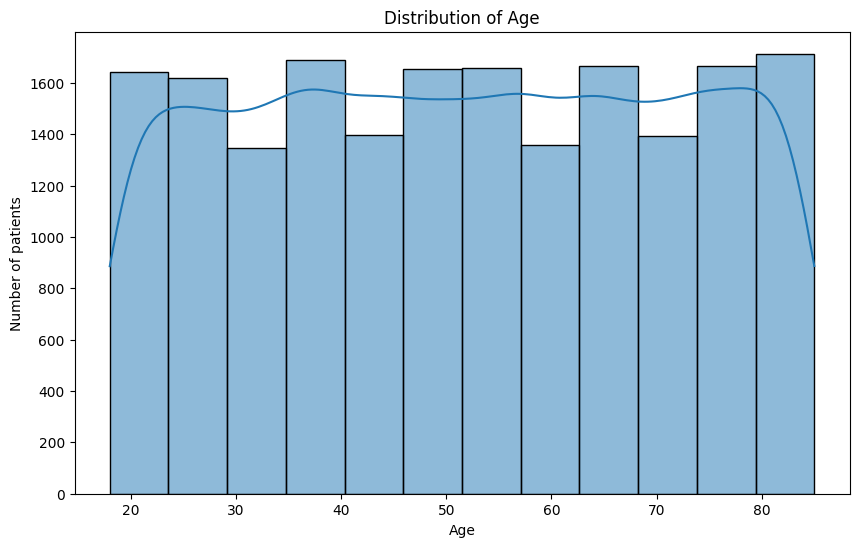

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,x="Age",bins=12,kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Number of patients")
plt.show()



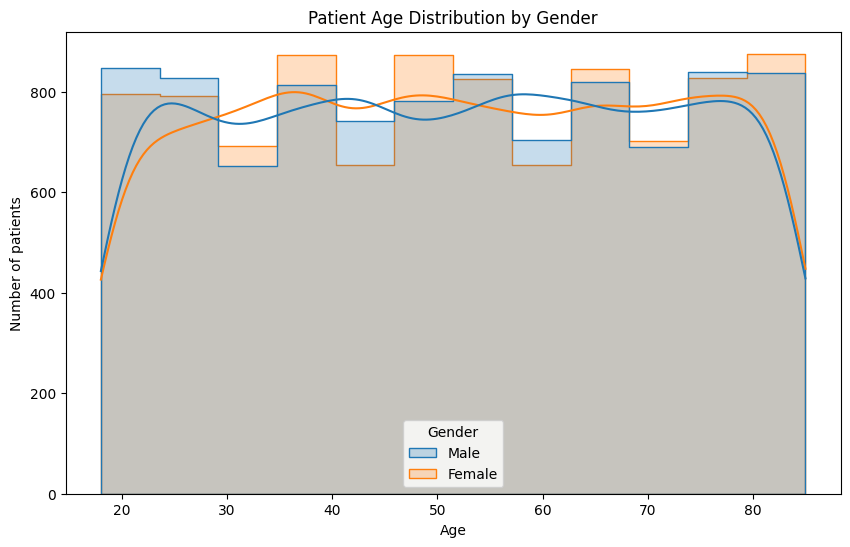

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,x="Age",hue="Gender",bins=12,kde=True,element="step")
plt.title("Patient Age Distribution by Gender")
plt.xlabel("Age")
plt.ylabel("Number of patients")
plt.show()

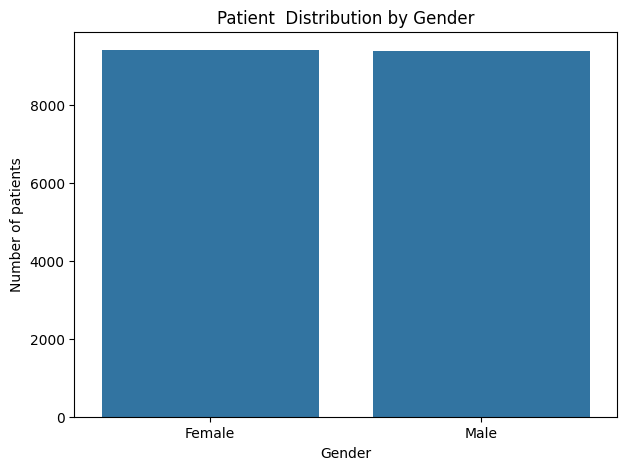

In [ ]:
gender_counts=df["Gender"].value_counts()
plt.figure(figsize=(7,5))
sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values,)
plt.title("Patient  Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of patients")
plt.show()

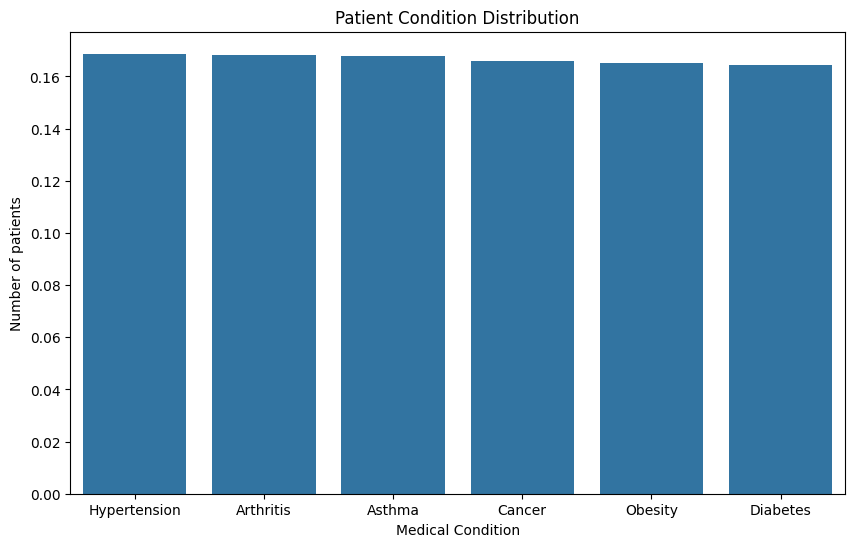

In [ ]:
condition_counts=df["Medical_Condition"].value_counts(
    plt.figure(figsize=(10,6))
)
sns.barplot(
    x=condition_counts.index,
    y=condition_counts.values,
)

plt.title("Patient Condition Distribution")
plt.xlabel("Medical Condition")
plt.ylabel("Number of patients")
plt.show()

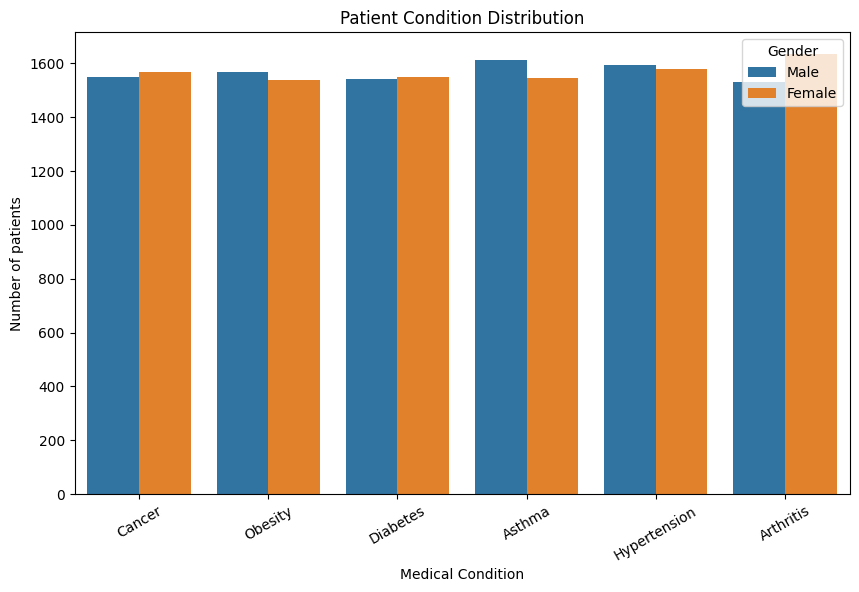

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(data=df,x="Medical_Condition",hue="Gender")
plt.title("Patient Condition Distribution")
plt.xlabel("Medical Condition")
plt.ylabel("Number of patients")
plt.xticks(rotation=30)
plt.show()

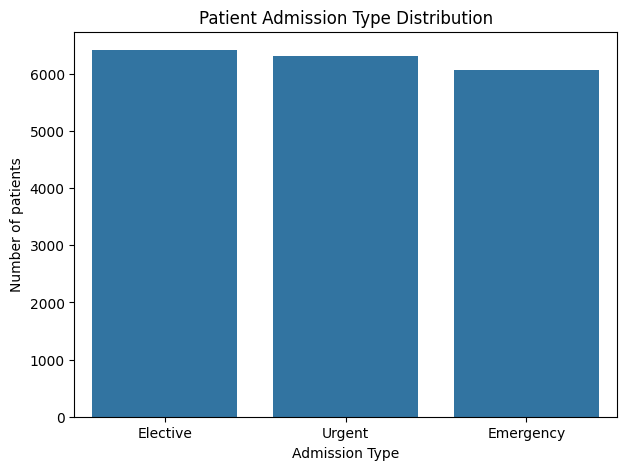

In [ ]:
admission_counts=df["Admission_Type"].value_counts()
plt.figure(figsize=(7,5))
sns.barplot(
    x=admission_counts.index,
    y=admission_counts.values,
)
plt.title("Patient Admission Type Distribution")
plt.xlabel("Admission Type")
plt.ylabel("Number of patients")
plt.show()

In [ ]:
admission_condition=pd.crosstab(df["Admission_Type"],df["Medical_Condition"])
print(admission_condition)

Medical_Condition  Arthritis  Asthma  Cancer  Diabetes  Hypertension  Obesity
Admission_Type                                                               
Elective                1080    1113    1081      1032          1099     1014
Emergency               1012    1012     991       989          1029     1031
Urgent                  1071    1032    1045      1069          1045     1061


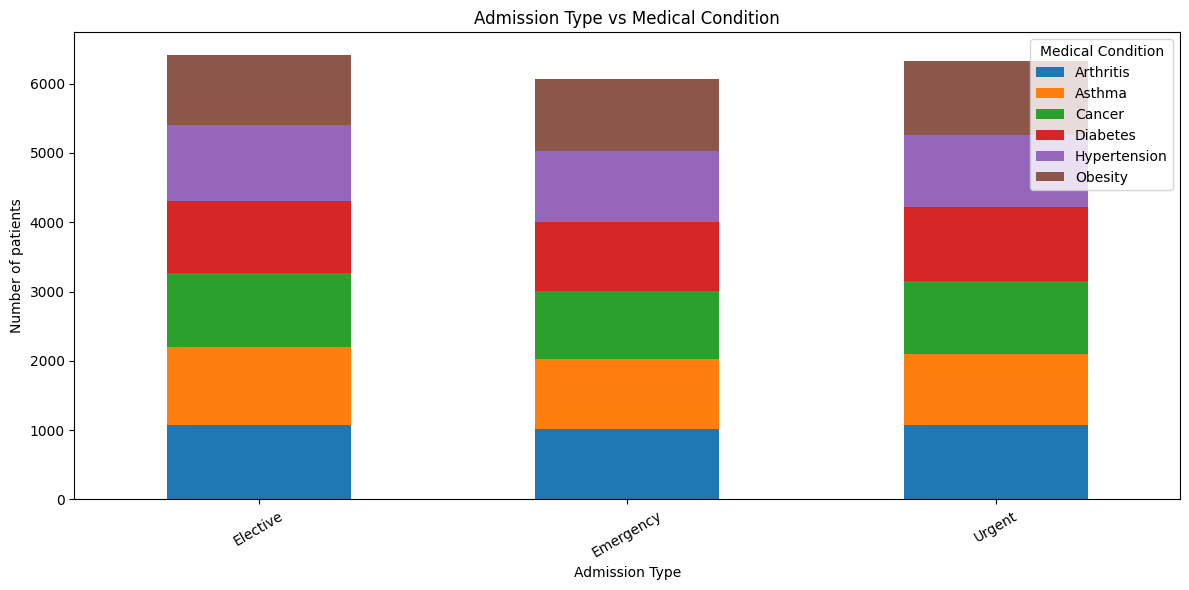

In [ ]:
admission_condition.plot(kind="bar",figsize=(12,6),stacked=True)
plt.title("Admission Type vs Medical Condition")
plt.xlabel("Admission Type")
plt.ylabel("Number of patients")
plt.xticks(rotation=30)
plt.legend(title="Medical Condition")
plt.tight_layout()
plt.show()

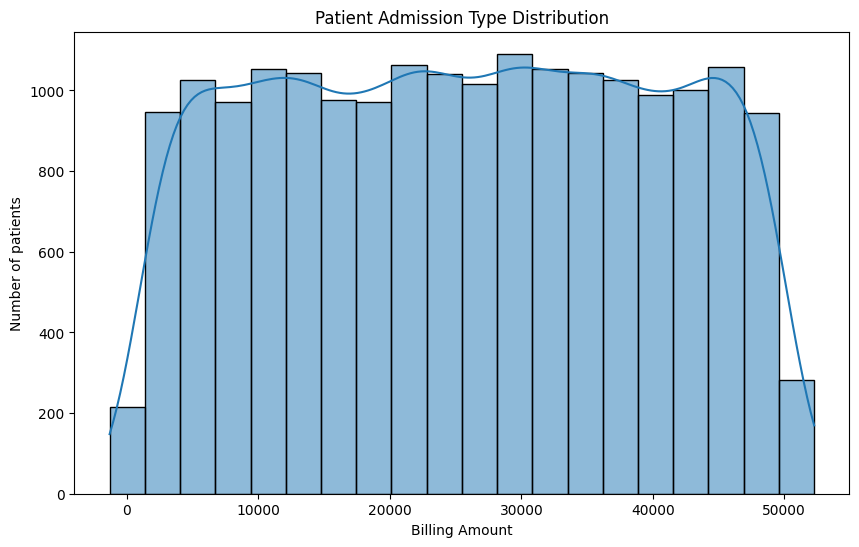

In [ ]:
plt.figure(figsize=(10,6))
sns.histplot(data=df,x="Billing_Amount",bins=20,kde=True)
plt.title("Patient Admission Type Distribution")
plt.xlabel("Billing Amount")
plt.ylabel("Number of patients")
plt.show()

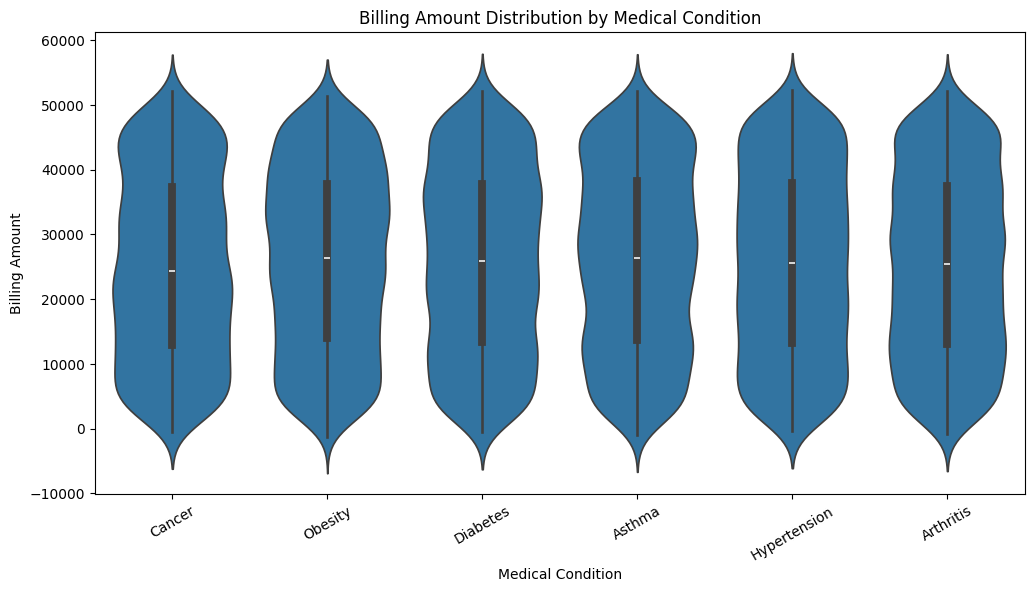

In [ ]:
plt.figure(figsize=(12,6))
sns.violinplot(data=df,x="Medical_Condition",y="Billing_Amount")
plt.title("Billing Amount Distribution by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.show()

In [ ]:
avg_condition_billing=(df.groupby("Medical_Condition")["Billing_Amount"].mean().sort_values(ascending=False))
print(avg_condition_billing)

Medical_Condition
Asthma          26048.980037
Obesity         25921.833709
Diabetes        25757.674816
Hypertension    25591.647555
Arthritis       25407.013328
Cancer          25108.850573
Name: Billing_Amount, dtype: float64


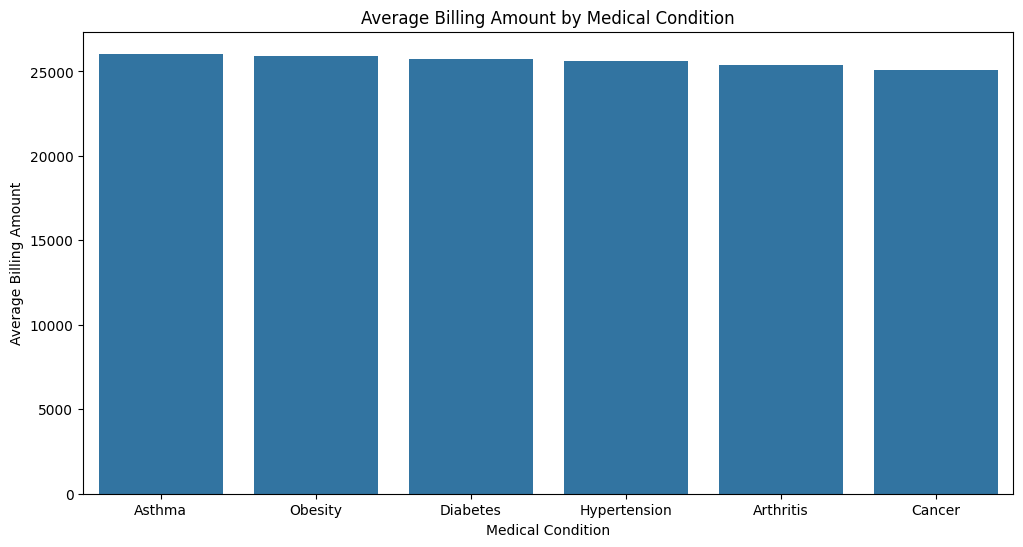

In [ ]:
plt.figure(figsize=(12,6))
sns.barplot(x=avg_condition_billing.index,y=avg_condition_billing.values)
plt.title("Average Billing Amount by Medical Condition")
plt.title("Average Billing Amount by Medical Condition")
plt.xlabel("Medical Condition")
plt.ylabel("Average Billing Amount")
plt.show()

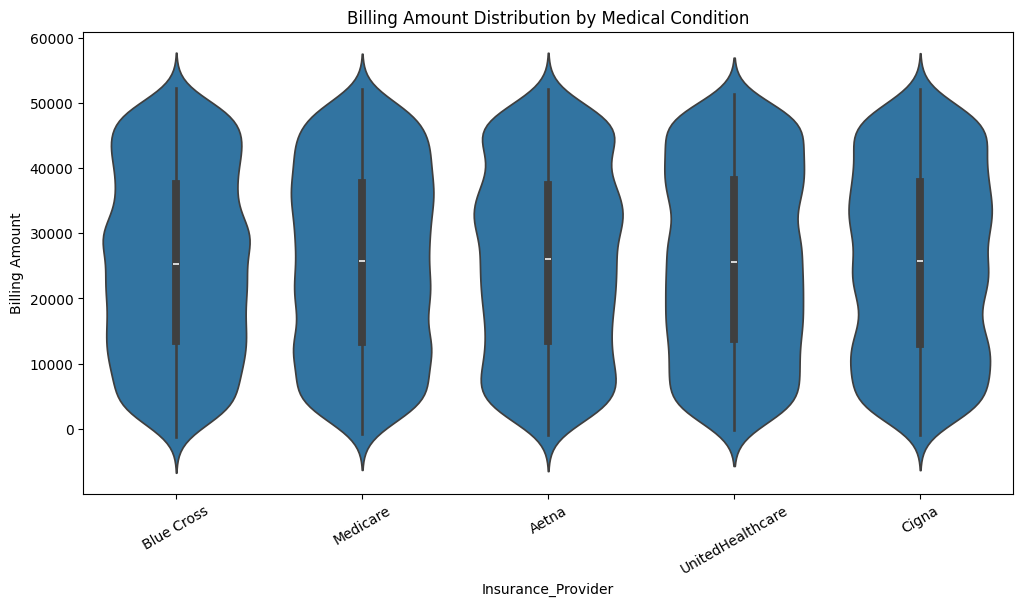

In [ ]:
plt.figure(figsize=(12,6))
sns.violinplot(data=df,x="Insurance_Provider",y="Billing_Amount")
plt.title("Billing Amount Distribution by Medical Condition")
plt.xlabel("Insurance_Provider")
plt.ylabel("Billing Amount")
plt.xticks(rotation=30)
plt.show()

In [ ]:
Insurance_billing=(df.groupby("Insurance_Provider")["Billing_Amount"].mean().sort_values(ascending=False))
print(Insurance_billing)

Insurance_Provider
UnitedHealthcare    25786.289561
Aetna               25675.527349
Medicare            25644.700759
Cigna               25598.137288
Blue Cross          25494.081531
Name: Billing_Amount, dtype: float64


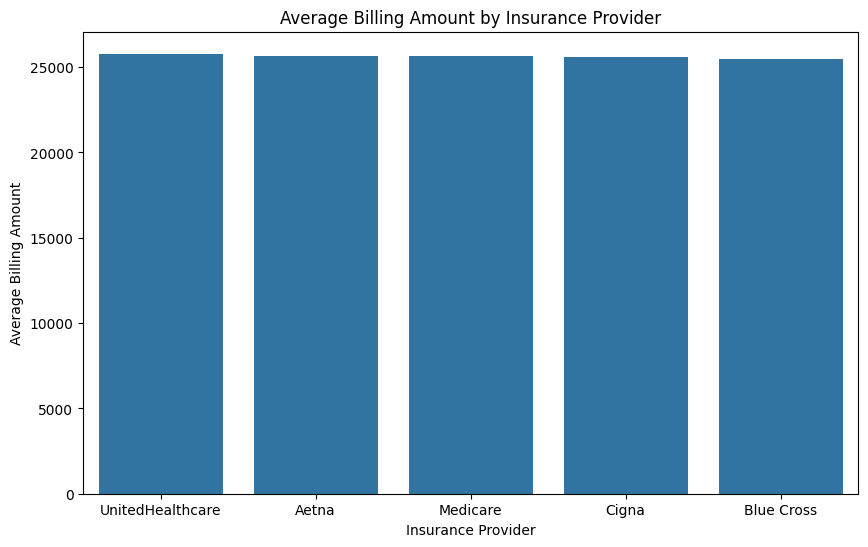

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(x=Insurance_billing.index,y=Insurance_billing.values)
plt.title("Average Billing Amount by Insurance Provider")
plt.xlabel("Insurance Provider")
plt.ylabel("Average Billing Amount")
plt.show()

In [ ]:
df["Admission_Date"]=pd.to_datetime(df["Admission_Date"])
df["Admission_Month"]=(df["Admission_Date"].dt.to_period("M"))

In [ ]:
monthly_admissions=(df.groupby("Admission_Month").size().reset_index(name="Admissions"))


In [ ]:
monthly_admissions["Admission_Month"]=(monthly_admissions["Admission_Month"].dt.to_timestamp())

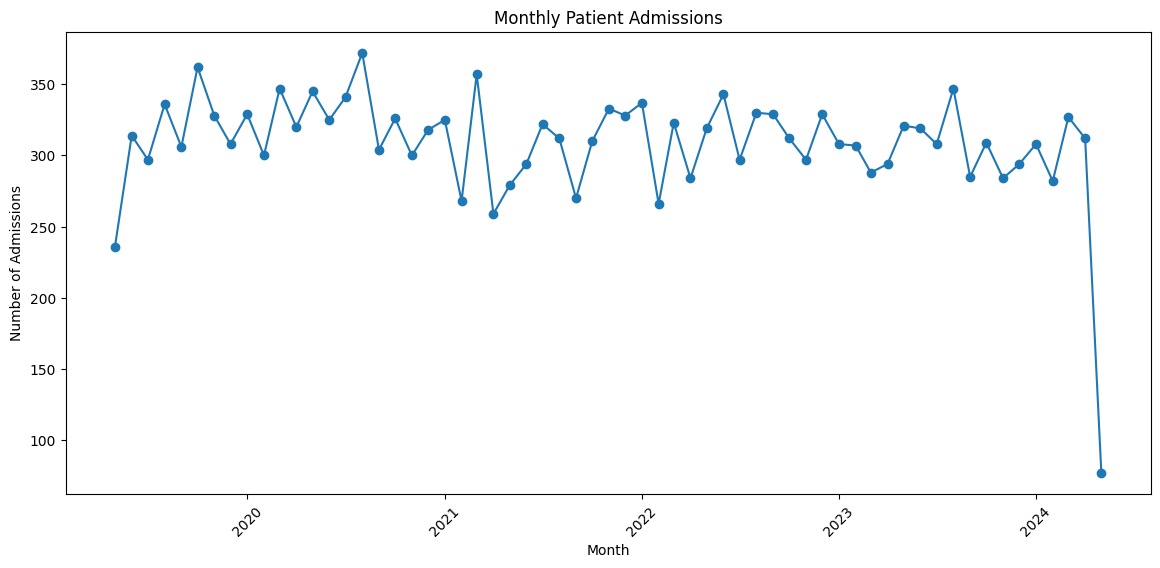

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(monthly_admissions["Admission_Month"],monthly_admissions["Admissions"],marker="o")
plt.title("Monthly Patient Admissions")
plt.xlabel("Month")
plt.ylabel("Number of Admissions")
plt.xticks(rotation=45)
plt.show()